# Risk attribution with Student t distributed risk drivers



In [8]:
import sys
sys.path.insert(0,'/Users/martincaroe/Desktop/MARTIN/Copenhagen Business School/Msc Economics and Business Administration - Finance and Investments /3 Semester/Python for the Financial Economics/Fork/python_for_the_financial_economist')

# import relevant packages
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# from codelib
from codelib.visualization.base import risk_waterfall_chart, waterfall_chart

from codelib.visualization.layout import DefaultStyle
DefaultStyle();

Assume that we can specify the return of an asset using the following decomposition

$$
\mathbf{R} = \alpha + \beta_1 \mathbf{Z}_1 + \beta_2 \mathbf{Z}_2 + \varepsilon = \boldsymbol{\beta}^\top \mathbf{Z}
$$

where $\boldsymbol{\beta} = (\beta_1, \beta_2, 1)^\top = (0.5, 0.75, 1)^\top$ and 

$$
\mathbf{Z} = \begin{pmatrix} \mathbf{Z}_1 \\ \mathbf{Z}_2 \\ \alpha + \varepsilon  \end{pmatrix} \sim t(\boldsymbol{\mu}, \boldsymbol{\Sigma}, \nu)
$$

Assume that $\nu = 10$ and 

$$
\boldsymbol{\mu} = \begin{pmatrix} 0.04 \\ 0.08 \\ 0.0\end{pmatrix}
$$

and 

$$
\boldsymbol{\Sigma} = \begin{pmatrix} 0.1^2 & 0 & 0 \\ 0 & 0.15^2 & 0 \\ 0 & 0 & 0.05^2 \end{pmatrix}
$$

In [3]:
"""
Setup
"""
mu = np.array([0.04, 0.08, 0.0])
Sigma = np.diag([0.1**2, 0.15**2, 0.05**2])
beta = np.array([0.5, 0.75, 1.0])
nu = 10

## Problem 1

The variance of $\mathbf{R}$ is given by 

$$
\text{Var}[\mathbf{R}] = \boldsymbol{\beta}^\top \text{Cov}[\mathbf{Z}]  \boldsymbol{\beta}
$$

What is the variance of $\mathbf{R}$? What is the standard deviation?

In [4]:
"""
Variance and std. of R
"""
cov_Z = nu / (nu - 2) * Sigma
var_R = beta @ cov_Z @ beta
std_R = np.sqrt(var_R)

print('Variance of R:', var_R)
print('Std. of R:', std_R)

Variance of R: 0.022070312499999998
Std. of R: 0.1485608040500589


**Tolkning:** Before we can measure risk, we need the actual covariance — and for a t-distribution, that covariance is always LARGER than the scale matrix Σ itself (scaled up by ν/(ν-2)). Forgetting this factor would make us underestimate the true risk.

## Problem 2

Following similar arguments as for a portfolio, the Euler decomposition of the standard devation of the asset return reads

$$
\sigma_R(\boldsymbol{\beta}) = \boldsymbol{\beta}^\top \frac{\text{Cov}[\mathbf{Z}]  \boldsymbol{\beta}}{\sqrt{\boldsymbol{\beta}^\top \text{Cov}[\mathbf{Z}] \boldsymbol{\beta}}} = \sum_{i=1}^3 \beta_i \frac{(\text{Cov}[\mathbf{Z}] \boldsymbol{\beta})_i }{\sqrt{\boldsymbol{\beta}^\top \text{Cov}[\mathbf{Z}] \boldsymbol{\beta}}}
$$

Attribute the risk using the above decomposition. Does the risk contributions sum to the total risk? Plot the results. 

Risk contributions: [0.02103516 0.10649049 0.02103516]
Sum: 0.14856080405005895 (should equal std_R: 0.1485608040500589 )


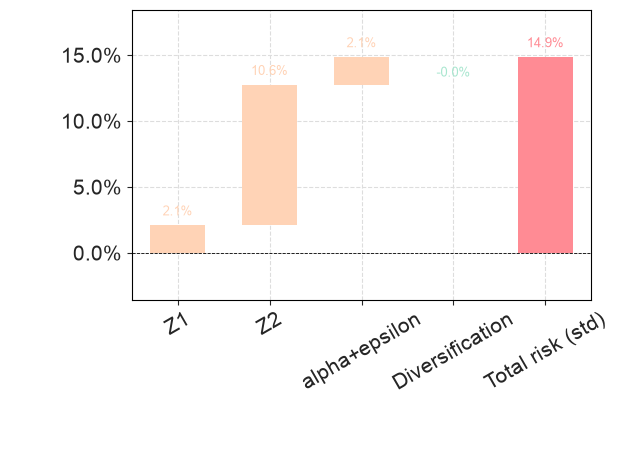

In [9]:
"""
Euler decomposition of std.
"""
risk_contrib_std = beta * (cov_Z @ beta) / std_R

print('Risk contributions:', risk_contrib_std)
print('Sum:', risk_contrib_std.sum(), '(should equal std_R:', std_R, ')')

fig, ax = risk_waterfall_chart(risk_contrib_std * 100, std_R * 100,
                                 names=["Z1", "Z2", "alpha+epsilon"],
                                 formatting='{:,.1f}%', total_risk_label="Total risk (std)")

**Tolkning:** Same Euler trick from Lecture 4, just applied to this specific asset's 3 risk drivers instead of a portfolio's assets. The 3 contributions should add up EXACTLY to the total standard deviation — that's the whole point of Euler's theorem (it's an exact split, not an approximation).

## Problem 3

We have the general result that if $\mathbf{Z} \sim t(\boldsymbol{\mu}, \boldsymbol{\Sigma}, \nu)$ then

$$
\boldsymbol{a} + \boldsymbol{b} \mathbf{Z} \sim t(\boldsymbol{a}+\boldsymbol{b} \boldsymbol{\mu},\boldsymbol{b} \boldsymbol{\Sigma} \boldsymbol{b}^\top, \nu)
$$

Calculate the $\text{VaR}_{5\%} (\mathbf{R})$.

In [10]:
"""
VaR at 5% using the t-distribution transformation rule
"""
mu_R = beta @ mu
scale2_R = beta @ Sigma @ beta  # note: uses Sigma directly, NOT cov_Z!
scale_R = np.sqrt(scale2_R)

q_alpha = stats.t.ppf(0.05, df=nu)
VaR_R = -(mu_R + scale_R * q_alpha)

print('VaR_5%(R):', VaR_R)

VaR_5%(R): 0.16083407519251108


**Tolkning:** This uses the SCALE matrix Σ directly (not the inflated covariance from Problem 1) — that's just how the t-distribution's own parameters work when combining variables linearly. The result tells us: there's a 5% chance this asset loses more than about 16% of its value.

## Problem 4

We have the general result that if $\mathbf{R} \sim t(\mu, \sigma^2, \nu)$ then

$$
R = \mu + \sigma Y
$$

where $Y \sim t(0, 1, \nu)$. Using this result will enable us to define the Euler decomposition 

$$
\text{VaR}_{\alpha} (\mathbf{R}) = \boldsymbol{\beta}^\top (-\boldsymbol{\mu} - \frac{\boldsymbol{\Sigma}  \boldsymbol{\beta}}{\sqrt{\boldsymbol{\beta}^\top \boldsymbol{\Sigma} \boldsymbol{\beta}}} q_t(\alpha))
$$

where $q_t(\alpha)$ is the quantile of a $t(0, 1, \nu)$ distributed random variable. 

Attribute the risk using the above decomposition. Does the risk contributions sum to the total risk? Plot the results. 

VaR contributions: [0.0141004  0.11263328 0.0341004 ]
Sum: 0.16083407519251108 (should equal VaR_R: 0.16083407519251108 )


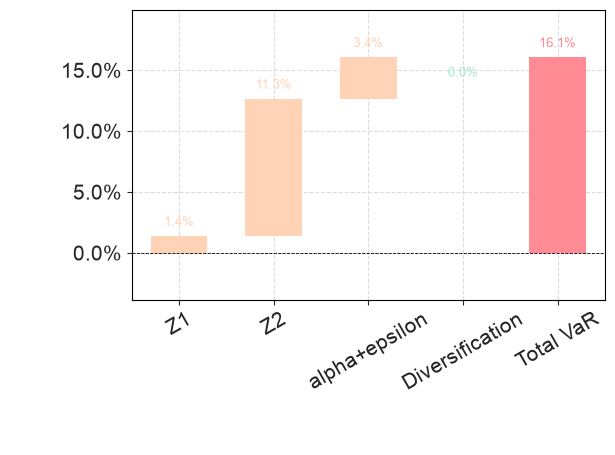

In [12]:
"""
Euler decomposition of VaR
"""
contrib_VaR = beta * (-mu - (Sigma @ beta) / scale_R * q_alpha)

print('VaR contributions:', contrib_VaR)
print('Sum:', contrib_VaR.sum(), '(should equal VaR_R:', VaR_R, ')')

fig, ax = risk_waterfall_chart(contrib_VaR * 100, VaR_R * 100,
                                 names=["Z1", "Z2", "alpha+epsilon"],
                                 formatting='{:,.1f}%', total_risk_label="Total VaR")


**Tolkning:** Euler decomposition isn't limited to standard deviation — as long as a risk measure is homogeneous of degree 1 (VaR is), we can split it fairly among factors the same way. Just like in Problem 2, these 3 contributions add up exactly to the total VaR from Problem 3.

**Key takeaway**
 for hele øvelsen: Euler decomposition works for ANY homogeneous risk measure, not just standard deviation — here we applied the exact same logic to VaR under a t-distribution. The math changes (you need the t-distribution's quantile function instead of the Normal one), but the underlying idea — split total risk fairly among the factors that create it — stays identical.